<a href="https://colab.research.google.com/github/shahriarshadhin3-alt/uterine-emg-preterm-detection/blob/main/notebooks/04_time_domain_feature_extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 04 - Time-Domain Feature Extraction

## Project
Uterine EMG Analysis for Preterm Birth Detection

## Objective
Extract time-domain features from uterine EHG signals.

## Tasks
1. Load a TPEHG recording.
2. Select a filtered EHG channel.
3. Remove filter transient regions.
4. Calculate statistical features.
5. Calculate waveform features.
6. Create a feature vector.
7. Visualize feature characteristics.

In [1]:
!pip install -q wfdb PyWavelets

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the recording

record = wfdb.rdrecord(
    "tpehg1007",
    pn_dir="tpehgdb/1.0.1/tpehgdb"
)

fs = record.fs

print("Sampling frequency:", fs)
print("Signal shape:", record.p_signal.shape)

Sampling frequency: 20
Signal shape: (35180, 12)


In [4]:
# Column 1 = S1 filtered (0.08–4 Hz)

signal = record.p_signal[:, 1]

# Remove first and last 180 seconds

edge_samples = 180 * fs

clean_signal = signal[
    edge_samples:-edge_samples
]

print("Original samples:", len(signal))
print("Remaining samples:", len(clean_signal))
print("Remaining duration:", len(clean_signal)/fs, "seconds")

Original samples: 35180
Remaining samples: 27980
Remaining duration: 1399.0 seconds


In [5]:
# Basic time-domain features

mean_value = np.mean(clean_signal)

variance = np.var(clean_signal)

std_value = np.std(clean_signal)

rms = np.sqrt(np.mean(clean_signal**2))

peak_to_peak = (
    np.max(clean_signal) - np.min(clean_signal)
)

print("Mean:", mean_value)
print("Variance:", variance)
print("Standard Deviation:", std_value)
print("RMS:", rms)
print("Peak-to-Peak:", peak_to_peak)

Mean: -2.069893409896762e-05
Variance: 0.0007775806512675631
Standard Deviation: 0.027885133158505146
RMS: 0.027885140840839158
Peak-to-Peak: 0.26909285114824144


In [6]:
# Zero Crossing Rate

zero_crossings = np.sum(
    clean_signal[:-1] * clean_signal[1:] < 0
)

zcr = zero_crossings / (len(clean_signal) - 1)

print("Zero Crossing Rate:", zcr)

Zero Crossing Rate: 0.0383501912148397


In [7]:
# Waveform Length

waveform_length = np.sum(
    np.abs(np.diff(clean_signal))
)

print("Waveform Length:", waveform_length)

Waveform Length: 83.86472877088579


In [11]:
# Create feature dictionary

features = {
    "Mean": mean_value,
    "Variance": variance,
    "Standard_Deviation": std_value,
    "RMS": rms,
    "Peak_to_Peak": peak_to_peak,
    "Zero_Crossing_Rate": zcr,
    "Waveform_Length": waveform_length
}

# Convert dictionary into DataFrame

feature_df = pd.DataFrame(
    [features]
)

display(feature_df)

,Mean,Variance,Standard_Deviation,RMS,Peak_to_Peak,Zero_Crossing_Rate,Waveform_Length
0,-0.000021,0.000778,0.027885,0.027885,0.269093,0.03835,83.864729


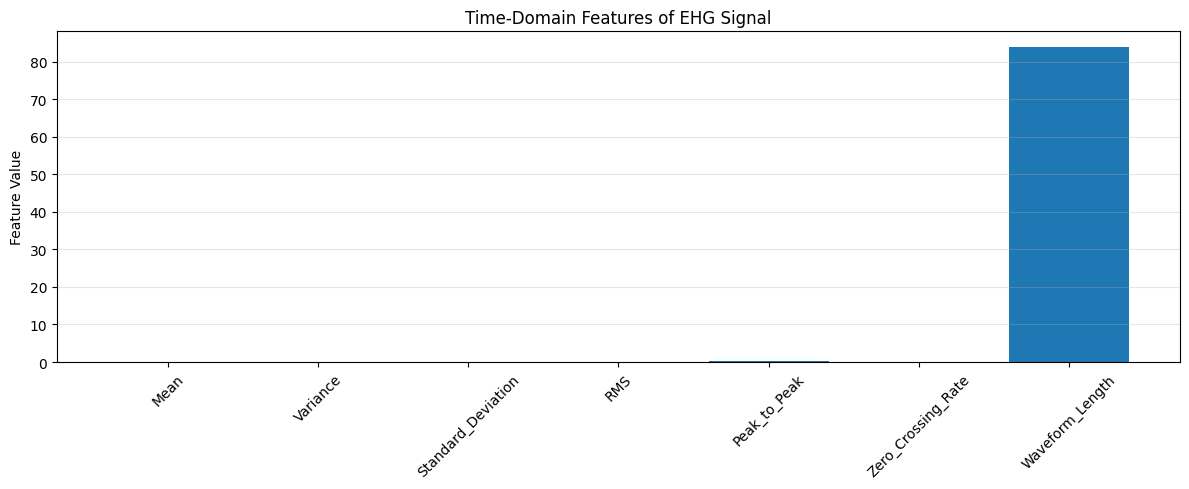

In [12]:
# Visualize feature values

feature_names = list(features.keys())

feature_values = list(features.values())

plt.figure(figsize=(12, 5))

plt.bar(feature_names, feature_values)

plt.title("Time-Domain Features of EHG Signal")
plt.ylabel("Feature Value")
plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()